# Ejemplo 5. Diagrama de Bode de un sistema de segundo orden con un cero real

**Instrumentación y Control — Cuaderno de desarrollo**

Consideremos la función de transferencia

$$
\boxed{G(s)=\frac{10(s+10)}{s^2+6s+100}.}
$$

El objetivo es construir e interpretar el diagrama de Bode, identificando las contribuciones del par de polos complejos y del cero real, y comparando la magnitud **exacta** con su **aproximación asintótica**.

Trabajaremos directamente con esta función de transferencia, sin reescribirla en forma normalizada.

## 1. Identificación de los polos, el cero y la ganancia estática

La función tiene:

- Un **cero real** en $s=-10$; su frecuencia de quiebre es $\omega_z=10\ \mathrm{rad/s}$.
- Un **par de polos complejos** cuyo denominador es $s^2+6s+100$. Comparándolo con $s^2+2\zeta\omega_n s+\omega_n^2$, obtenemos $\omega_n=10\ \mathrm{rad/s}$ y $\zeta=0.3$.
- **Ganancia estática unitaria**: $G(0)=10(10)/100=1$, equivalente a $0\ \mathrm{dB}$.

Verifiquemos estos datos numéricamente.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Coeficientes del modelo original G(s) = 10(s+10)/(s²+6s+100)
numerador = [10, 100]
denominador = [1, 6, 100]

ceros = np.roots(numerador)
polos = np.roots(denominador)
omega_n = np.sqrt(denominador[-1])
zeta = denominador[1] / (2 * omega_n)
omega_z = -ceros[0].real
G_0 = np.polyval(numerador, 0) / np.polyval(denominador, 0)

print('Cero:', np.round(ceros, 4))
print('Polos:', np.round(polos, 4))
print(f'Frecuencia natural: ω_n = {omega_n:.2f} rad/s')
print(f'Amortiguamiento: ζ = {zeta:.2f}')
print(f'Frecuencia de quiebre del cero: ω_z = {omega_z:.2f} rad/s')
print(f'Ganancia estática: G(0) = {G_0:.2f}  →  {20*np.log10(abs(G_0)):.2f} dB')

Cero: [-10.]
Polos: [-3.+9.5394j -3.-9.5394j]
Frecuencia natural: ω_n = 10.00 rad/s
Amortiguamiento: ζ = 0.30
Frecuencia de quiebre del cero: ω_z = 10.00 rad/s
Ganancia estática: G(0) = 1.00  →  0.00 dB


## 2. Magnitud y fase exactas

Evaluando la función directamente en $s=j\omega$:

$$
G(j\omega)=\frac{10(10+j\omega)}{(100-\omega^2)+j6\omega}.
$$

Su magnitud es

$$
\boxed{|G(j\omega)|=\frac{10\sqrt{100+\omega^2}}{\sqrt{(100-\omega^2)^2+(6\omega)^2}}.}
$$

La fase se obtiene restando el ángulo del denominador al del numerador:

$$
\boxed{\phi(\omega)=\tan^{-1}\!\left(\frac{\omega}{10}\right)-\operatorname{atan2}(6\omega,100-\omega^2).}
$$

La función `atan2` permite reconocer correctamente el cuadrante del ángulo del denominador. Para representar la magnitud en decibelios usamos $M(\omega)=20\log_{10}|G(j\omega)|$.

  ω (rad/s)   Magnitud (dB)    Fase (°)
       0.1          0.00           0.23
       1.0          0.11           2.24
       5.0          2.82           4.76
      10.0          7.45         -45.00
      20.0         -3.20         -94.76
     100.0        -19.89         -92.24
    1000.0        -40.00         -90.23


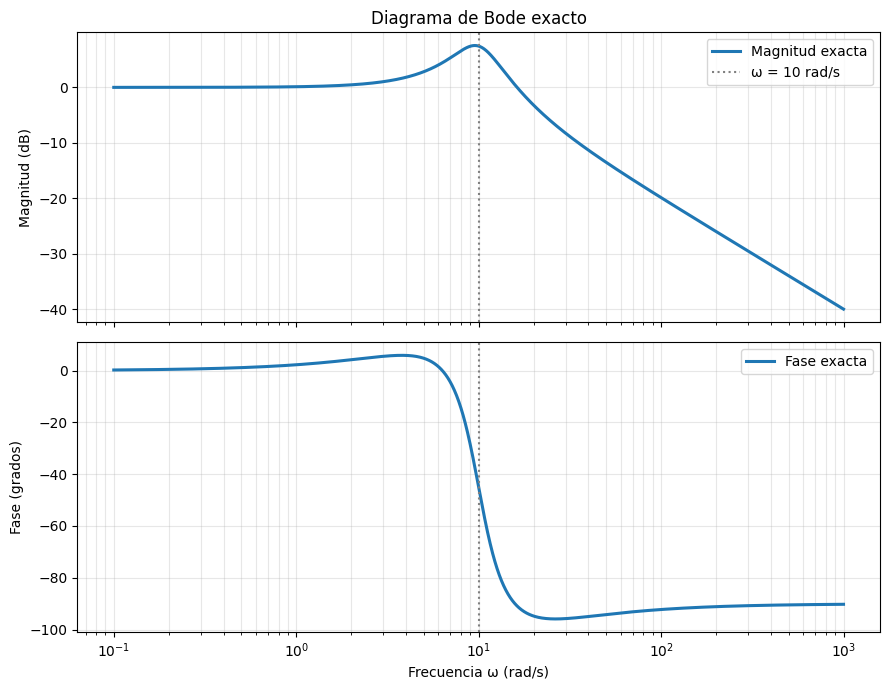

In [2]:
# Frecuencias de análisis, en rad/s
omega = np.logspace(-1, 3, 2000)
s = 1j * omega

# Evaluación directa: no es necesario normalizar la función de transferencia.
G_jw = np.polyval(numerador, s) / np.polyval(denominador, s)
M_exacta = 20 * np.log10(np.abs(G_jw))
fase_exacta = np.degrees(np.unwrap(np.angle(G_jw)))

print('  ω (rad/s)   Magnitud (dB)    Fase (°)')
for w0 in [0.1, 1, 5, 10, 20, 100, 1000]:
    valor = np.polyval(numerador, 1j*w0) / np.polyval(denominador, 1j*w0)
    print(f'  {w0:8.1f}     {20*np.log10(abs(valor)):9.2f}       {np.degrees(np.angle(valor)):8.2f}')

fig, (ax_m, ax_f) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax_m.semilogx(omega, M_exacta, linewidth=2.2, label='Magnitud exacta')
ax_m.axvline(10, color='gray', linestyle=':', label='ω = 10 rad/s')
ax_m.set_ylabel('Magnitud (dB)')
ax_m.set_title('Diagrama de Bode exacto')
ax_m.grid(True, which='both', alpha=0.3)
ax_m.legend()

ax_f.semilogx(omega, fase_exacta, linewidth=2.2, label='Fase exacta')
ax_f.axvline(10, color='gray', linestyle=':')
ax_f.set_ylabel('Fase (grados)')
ax_f.set_xlabel('Frecuencia ω (rad/s)')
ax_f.grid(True, which='both', alpha=0.3)
ax_f.legend()
plt.tight_layout()
plt.show()

## 3. Contribución del cero y del par de polos

Para estudiar la construcción del diagrama, separaremos las contribuciones a **magnitud** y **fase**. Cada contribución de magnitud se expresa respecto a su valor de baja frecuencia, de modo que ambas parten de $0\ \mathrm{dB}$ y su suma reproduce la magnitud total:

$$
M_z(\omega)=20\log_{10}\!\left(\frac{\sqrt{10^2+\omega^2}}{10}\right),
$$

$$
M_p(\omega)=20\log_{10}\!\left(\frac{100}{\sqrt{(100-\omega^2)^2+(6\omega)^2}}\right).
$$

Por tanto, $M(\omega)=M_z(\omega)+M_p(\omega)$, dado que $G(0)=1$.

Para la fase:

$$
\phi_z(\omega)=\tan^{-1}(\omega/10),\qquad
\phi_p(\omega)=-\operatorname{atan2}(6\omega,100-\omega^2),
$$

$$\phi(\omega)=\phi_z(\omega)+\phi_p(\omega).$$

El cero aporta fase positiva y el par de polos aporta fase negativa. Observe cómo se combinan las curvas.

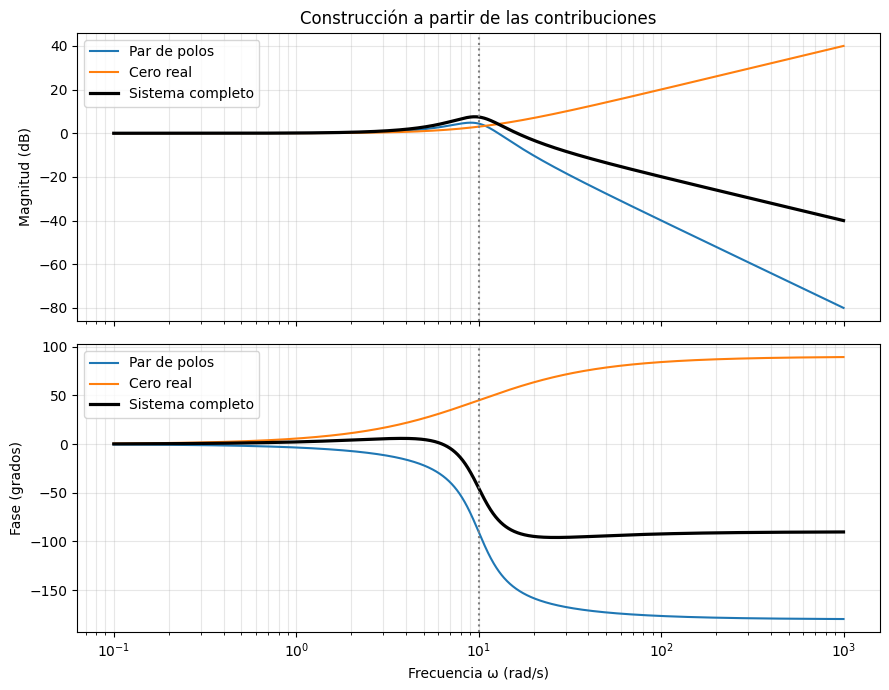

In [3]:
# Magnitudes de cada contribución (referidas a 0 dB en baja frecuencia)
M_cero = 20 * np.log10(np.sqrt(100 + omega**2) / 10)
M_polos = 20 * np.log10(100 / np.sqrt((100 - omega**2)**2 + (6*omega)**2))
M_suma = M_cero + M_polos

# Fases de cada contribución, en grados
fase_cero = np.degrees(np.arctan2(omega, 10))
fase_polos = -np.degrees(np.arctan2(6*omega, 100 - omega**2))
fase_suma = fase_cero + fase_polos

assert np.allclose(M_suma, M_exacta, atol=1e-10)
assert np.allclose(fase_suma, fase_exacta, atol=1e-10)

fig, (ax_m, ax_f) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax_m.semilogx(omega, M_polos, label='Par de polos')
ax_m.semilogx(omega, M_cero, label='Cero real')
ax_m.semilogx(omega, M_suma, color='black', linewidth=2.3, label='Sistema completo')
ax_m.axvline(10, color='gray', linestyle=':')
ax_m.set_ylabel('Magnitud (dB)')
ax_m.set_title('Construcción a partir de las contribuciones')
ax_m.grid(True, which='both', alpha=0.3)
ax_m.legend()

ax_f.semilogx(omega, fase_polos, label='Par de polos')
ax_f.semilogx(omega, fase_cero, label='Cero real')
ax_f.semilogx(omega, fase_suma, color='black', linewidth=2.3, label='Sistema completo')
ax_f.axvline(10, color='gray', linestyle=':')
ax_f.set_xlabel('Frecuencia ω (rad/s)')
ax_f.set_ylabel('Fase (grados)')
ax_f.grid(True, which='both', alpha=0.3)
ax_f.legend()
plt.tight_layout()
plt.show()

## 4. Construcción de la aproximación asintótica

Usamos únicamente las frecuencias características y las pendientes correspondientes:

| Factor | Frecuencia característica | Pendiente antes | Pendiente después |
|:--|--:|--:|--:|
| Par de polos complejos | $\omega_n=10\ \mathrm{rad/s}$ | $0$ dB/década | $-40$ dB/década |
| Cero real | $\omega_z=10\ \mathrm{rad/s}$ | $0$ dB/década | $+20$ dB/década |
| **Combinación** | $10\ \mathrm{rad/s}$ | **$0$ dB/década** | **$-20$ dB/década** |

Como la magnitud inicial es $0$ dB, la aproximación asintótica del sistema completo es

$$
\boxed{M_{\mathrm{as}}(\omega)=
\begin{cases}
0, & \omega\leq 10,\\[1mm]
-20\log_{10}(\omega/10), & \omega>10.
\end{cases}}
$$

Esta aproximación describe la tendencia general, pero **no reproduce el pico** generado por el bajo amortiguamiento del par de polos.

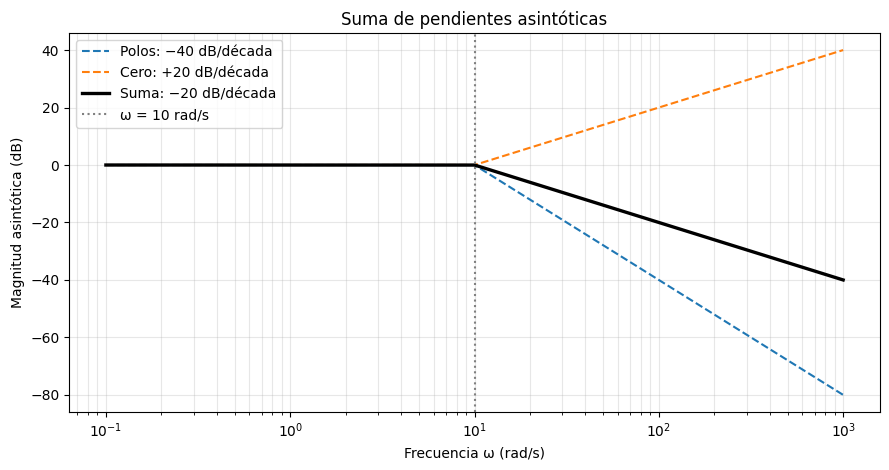

In [4]:
# Rectas asintóticas: ambas pendientes cambian en ω = 10 rad/s.
log_tramo = np.log10(np.maximum(omega / 10, 1))
M_polos_as = -40 * log_tramo
M_cero_as = +20 * log_tramo
M_asintotica = M_polos_as + M_cero_as

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.semilogx(omega, M_polos_as, linestyle='--', label='Polos: −40 dB/década')
ax.semilogx(omega, M_cero_as, linestyle='--', label='Cero: +20 dB/década')
ax.semilogx(omega, M_asintotica, color='black', linewidth=2.4,
            label='Suma: −20 dB/década')
ax.axvline(10, color='gray', linestyle=':', label='ω = 10 rad/s')
ax.set_xlabel('Frecuencia ω (rad/s)')
ax.set_ylabel('Magnitud asintótica (dB)')
ax.set_title('Suma de pendientes asintóticas')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 5. Bode exacto frente a aproximación asintótica

En la gráfica superior comparamos la magnitud exacta con la aproximación por rectas. En la inferior representamos la fase **exacta**; no necesitamos aproximarla por rectas para este ejemplo.

Preste atención a la región cercana a $10\ \mathrm{rad/s}$: allí se encuentran la frecuencia natural del par de polos y la frecuencia de quiebre del cero. Por eso, aunque la pendiente final es $-20$ dB/década, aparece un pico que las rectas no predicen.

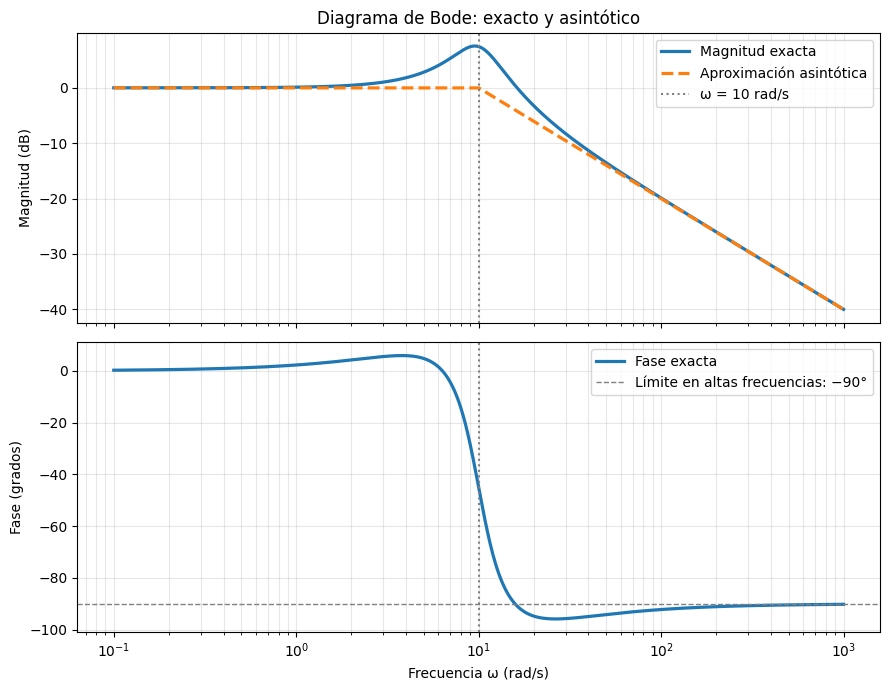

In [5]:
fig, (ax_m, ax_f) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax_m.semilogx(omega, M_exacta, linewidth=2.3, label='Magnitud exacta')
ax_m.semilogx(omega, M_asintotica, linestyle='--', linewidth=2.3,
              label='Aproximación asintótica')
ax_m.axvline(10, color='gray', linestyle=':', label='ω = 10 rad/s')
ax_m.set_ylabel('Magnitud (dB)')
ax_m.set_title('Diagrama de Bode: exacto y asintótico')
ax_m.grid(True, which='both', alpha=0.3)
ax_m.legend()

ax_f.semilogx(omega, fase_exacta, linewidth=2.3, label='Fase exacta')
ax_f.axvline(10, color='gray', linestyle=':')
ax_f.axhline(-90, color='gray', linestyle='--', linewidth=1,
             label='Límite en altas frecuencias: −90°')
ax_f.set_ylabel('Fase (grados)')
ax_f.set_xlabel('Frecuencia ω (rad/s)')
ax_f.grid(True, which='both', alpha=0.3)
ax_f.legend()
plt.tight_layout()
plt.show()

## 6. Identificación del máximo de magnitud

El par de polos, **si se considera aisladamente**, tiene su máximo en

$$
\omega_{r,\mathrm{polos}}=\omega_n\sqrt{1-2\zeta^2}
\quad\text{(para }0<\zeta<1/\sqrt{2}\text{).}
$$

Pero el **sistema completo también incluye el cero**, que modifica su magnitud y puede desplazar la frecuencia del máximo. Por ello conviene buscar el máximo del Bode total directamente, sin identificarlo automáticamente con $\omega_{r,\mathrm{polos}}$.

Frecuencia de resonancia del par de polos aislado: 9.055 rad/s
Frecuencia del máximo del sistema completo:      9.528 rad/s
Magnitud máxima del sistema completo:            7.551 dB
Magnitud exacta a ω = 10 rad/s:                 7.447 dB
Magnitud asintótica a ω = 10 rad/s:             0.000 dB


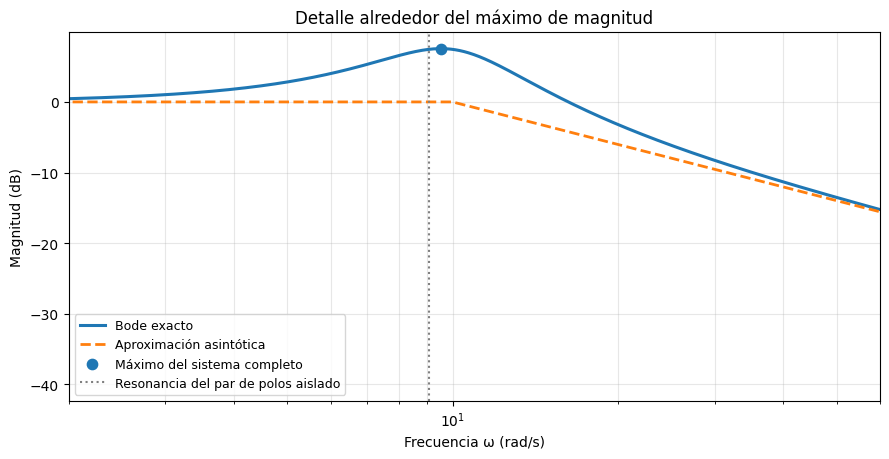

In [6]:
omega_r_polos = omega_n * np.sqrt(1 - 2*zeta**2)
indice_pico = np.argmax(M_exacta)
omega_pico = omega[indice_pico]
M_pico = M_exacta[indice_pico]

G_10 = np.polyval(numerador, 10j) / np.polyval(denominador, 10j)
print(f'Frecuencia de resonancia del par de polos aislado: {omega_r_polos:.3f} rad/s')
print(f'Frecuencia del máximo del sistema completo:      {omega_pico:.3f} rad/s')
print(f'Magnitud máxima del sistema completo:            {M_pico:.3f} dB')
print(f'Magnitud exacta a ω = 10 rad/s:                 {20*np.log10(abs(G_10)):.3f} dB')
print(f'Magnitud asintótica a ω = 10 rad/s:             0.000 dB')

fig, ax = plt.subplots(figsize=(9, 4.7))
ax.semilogx(omega, M_exacta, linewidth=2.2, label='Bode exacto')
ax.semilogx(omega, M_asintotica, linestyle='--', linewidth=2,
            label='Aproximación asintótica')
ax.scatter([omega_pico], [M_pico], s=55, zorder=5, label='Máximo del sistema completo')
ax.axvline(omega_r_polos, color='gray', linestyle=':',
           label='Resonancia del par de polos aislado')
ax.set_xlim(2, 60)
ax.set_xlabel('Frecuencia ω (rad/s)')
ax.set_ylabel('Magnitud (dB)')
ax.set_title('Detalle alrededor del máximo de magnitud')
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 7. Actividad de análisis

**Responda utilizando los resultados y gráficas del cuaderno:**

1. ¿Por qué la magnitud a bajas frecuencias es aproximadamente $0$ dB?
2. ¿Por qué la pendiente asintótica cambia directamente de $0$ a $-20$ dB/década cerca de $10\ \mathrm{rad/s}$?
3. ¿Por qué la aproximación asintótica no reproduce el máximo de magnitud?
4. ¿Por qué la fase del sistema completo tiende a $-90^\circ$ y no a $-180^\circ$?
5. ¿Por qué el máximo del sistema completo no ocurre exactamente a la misma frecuencia que la resonancia del par de polos aislado?

**Conclusión:** el diagrama de Bode de un sistema puede construirse combinando las contribuciones de sus ceros y polos. Las rectas asintóticas permiten anticipar pendientes y frecuencias características; la respuesta exacta revela detalles adicionales, especialmente cerca de la frecuencia natural de polos poco amortiguados.